# Scandinavia 2033 — meeting the European targets (and doing more)

**Common European targets for 2033 (as a group):**

| # | Target | How it is measured for Scandinavia here |
|---|---|---|
| 1 | −30 % GHG emissions | Scandinavian power-sector CO₂ ≤ 70 % of 2025 (modelled), + effect on Europe's CO₂ in the official model |
| 2 | Every country builds generation to its best | Cost-optimal investment (min. annualised CAPEX + FOM + fuel + CO₂ + trade) |
| 3 | RES +40 % | Wind + solar capacity ≥ 1.4 × 2025 |
| 4 | Interconnection ×2 | All Scandinavian borders doubled vs 2025 (8.8 → 17.6 GW) |
| 5 | Storage ≥ +20 % | Batteries + pumped hydro power ≥ 1.2 × 2025 |

**Reference year for every "+x %" is 2025 (today's ERAA fleet)**, which is also what the official European game model uses as default.

**Method**
1. Official ERAA-PyPSA European model (`my_little_europe_lt_uc.py`), full year, CY 1989, run by `run_europe_model.py` in a temporary copy of the repo (your input files are not modified):
   `baseline_2025` (today) and `reference_2033` (ERAA 2033 fleets everywhere + interconnections ×2) → neighbour prices and Europe's CO₂.
2. Hourly Scandinavia investment model (`scandi_model.py`, PuLP + HiGHS) — same cost data as `data_crunch.ipynb` Appendix D, plus hydro reservoirs, pumped hydro, batteries, demand response and trade with Germany / Benelux / Poland at the official model's hourly prices.
3. Scenarios: **S0** today, **S1** ERAA 2033 plan, **S2** targets at minimum cost, **S3** "do more".
4. The S2 and S3 plans are written as `scandinavia.json` files (official game format) and checked in the official European model.

Hydro data (reservoir inflows, run-of-river generation) is used exactly as given in the ERAA files — see section 2.


## Key results and recommendation (CY 1989, 2033)

**1. Targets.** With the ERAA 2033 plan, Scandinavia already exceeds RES (+175 %) and storage (+215 %). It **misses −30 % CO₂** (−22 %): its remaining emissions are the must-run fossil CHP/waste units ("Others non-renewable"). Doubling interconnection (8.8 → 17.6 GW) is part of the plan.

**2. Minimum-cost way to meet all targets (S2):** +16.7 GW onshore wind, +4.8 GW solar, +0.16 GW batteries, retire coal, oil and biomass, and cut fossil CHP from 0.74 to 0.51 GW. Cost 4.36 bn€/yr. Scandinavia ends up as neither a net exporter nor a net importer.

**3. Recommended — "do more" (S3):**

| | 2025 | **S3 2033** | change |
|---|---|---|---|
| Wind onshore | 39.3 GW | **70.8 GW** | +31.5 GW |
| Wind offshore / Solar PV | 2.4 / 12.1 GW | 2.4 / 12.1 GW | no new (onshore is cheaper per MWh in the Nordics) |
| Batteries (4 h) | 0.1 GW | **0.9 GW** | +0.8 GW → storage ×2 |
| Coal / Oil / Biomass | 0.87 / 1.58 / 3.27 GW | **0 / 0 / 0** | retired (biomass was never dispatched; it could be kept as a reserve) |
| Fossil CHP & waste | 0.74 GW | **0.05 GW** | phase-out |
| Gas CCGT | 3.3 GW | 3.3 GW | kept as backup, runs 0.29 TWh/yr |
| Nuclear / Hydro | 11.3 / 52.4 GW | unchanged | |
| Interconnection | 8.8 GW | **17.6 GW** | Germany 13.6, Benelux 2.8, Poland 1.2 |

Results: **CO₂ −90 %** (3.25 → 0.33 Mt), renewable share 76 %, **38 TWh net exports** (29.4 to Germany, 5.8 to Benelux, 3.0 to Poland), no unserved energy in any of the 6 climatic years, cost **5.6 bn€/yr** (+1.26 bn€ vs S2).

**4. Effect on Europe (official model, all other countries at ERAA 2033, borders ×2):** Europe's CO₂ goes from 20.6 Mt (2025) to **5.1 Mt with S3** (−75 %) and 5.8 Mt with S2 (−72 %), so the European −30 % target is met in both. The full ERAA plan for Scandinavia reaches 3.25 Mt, but costs 12.8 bn€/yr (huge offshore wind + solar build). The extra 1.84 Mt saved compared with S3 costs about 3,900 €/tCO₂, which is not worth it.

**Data:** all hydro inputs are the ERAA files as given (run-of-river 21.5 TWh/yr, reservoir inflow 124 TWh/yr, 109 TWh storage).

**Main assumptions / limits:** neighbours' prices are taken from the official model (Scandinavia is a price-taker); weather and prices from CY 1989; fossil CHP emits like gas at 40 % efficiency; no new nuclear before 2033; wind/solar potential ≤ 1.5 × ERAA 2033; CO₂ price 80 €/t. In S1, nuclear produces only 1.1 TWh because the model curtails it first when wind and solar are abundant; real plants would not.


In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scandi_model as sm

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)
HERE = Path.cwd()
RES = HERE / "results"; RES.mkdir(exist_ok=True)
VRES = ["wind_onshore", "wind_offshore", "solar_pv"]
CO2_PRICE = 80  # €/tCO2 in 2033, as in data_crunch.ipynb Appendix D (cell "Scenario parameters")
CY = 1989

## 1. Starting point (2025) and the targets

In [2]:
c25, c33 = sm.eraa_capacities(2025), sm.eraa_capacities(2033)
ic25 = sm.eraa_intercos(2025); ic2x = {k: 2 * v for k, v in ic25.items()}
vres25 = sum(c25[k] for k in VRES); sto25 = c25["batteries"] + c25["phs_turbine"]
vres33 = sum(c33[k] for k in VRES); sto33 = c33["batteries"] + c33["phs_turbine"]

targets = pd.DataFrame({
    "2025 (today)": [vres25 / 1e3, sto25 / 1e3, sum(ic25.values()) / 1e3],
    "2033 minimum target": [1.4 * vres25 / 1e3, 1.2 * sto25 / 1e3, 2 * sum(ic25.values()) / 1e3],
    "ERAA 2033 plan": [vres33 / 1e3, sto33 / 1e3, sum(ic25.values()) / 1e3],
}, index=["Wind + solar (GW)", "Storage: batteries + pumped hydro (GW)", "Interconnection (GW)"])
targets["ERAA plan vs target"] = targets["ERAA 2033 plan"] / targets["2033 minimum target"]
display(targets)

caps_cmp = pd.DataFrame({"2025": c25, "ERAA 2033": c33}) / 1e3
caps_cmp["change %"] = 100 * (caps_cmp["ERAA 2033"] / caps_cmp["2025"] - 1)
print("Installed capacities (GW; *_energy rows in GWh):")
display(caps_cmp)
print("Interconnection per border (MW):", ic25, "-> doubled:", ic2x)

,2025 (today),2033 minimum target,ERAA 2033 plan,ERAA plan vs target
Wind + solar (GW),53.87,75.42,147.99,1.96
Storage: batteries + pumped hydro (GW),0.81,0.97,2.55,2.63
Interconnection (GW),8.80,17.60,8.80,0.50


Installed capacities (GW; *_energy rows in GWh):


,2025,ERAA 2033,change %
nuclear,11.28,11.28,0.00
wind_onshore,39.32,71.70,82.36
wind_offshore,2.45,26.64,988.68
solar_pv,12.11,49.64,310.00
biofuel,3.27,2.65,-19.10
gas_ccgt,3.32,1.89,-43.10
gas_ocgt,0.00,0.00,NaN
coal,0.87,0.18,-78.81
oil,1.58,0.75,-52.66
others_renewable,6.99,6.86,-1.87


Interconnection per border (MW): {'germany': 6800.0, 'benelux': 1400.0, 'poland': 600.0} -> doubled: {'germany': 13600.0, 'benelux': 2800.0, 'poland': 1200.0}


## 2. Hydro data (ERAA files, as given)

| Hydro asset | Data used |
|---|---|
| Reservoir (46.7 GW, 109 TWh storage) | capacity + weekly natural inflows (ERAA 2024 values, same for every climatic year) |
| Pumped storage open loop (0.7 GW) | capacity, 75 % efficiency |
| Run-of-river (7.6 GW) | daily generation from `PECD-hydro-daily-ror-generation.csv`, spread evenly over each day |

,ror_capacity_2025_MW,ror_energy_GWh,capacity_factor_%
zone,,,
benelux,170.00,450.00,30.22
france,"13,600.00","39,502.39",33.16
germany,"3,933.90","15,573.53",45.19
iberian-peninsula,"3,679.44","8,603.95",26.69
italy,"7,028.60","19,134.42",31.08
poland,367.31,"1,362.19",42.34
scandinavia,"7,204.48","21,535.00",34.12


Scandinavian RoR (CY 1989): 21.5 TWh/yr, mean 2.46 GW (capacity 2033: 7.59 GW)
Reservoir inflow: 124.3 TWh/yr, storage 109.4 TWh, turbine 46.7 GW


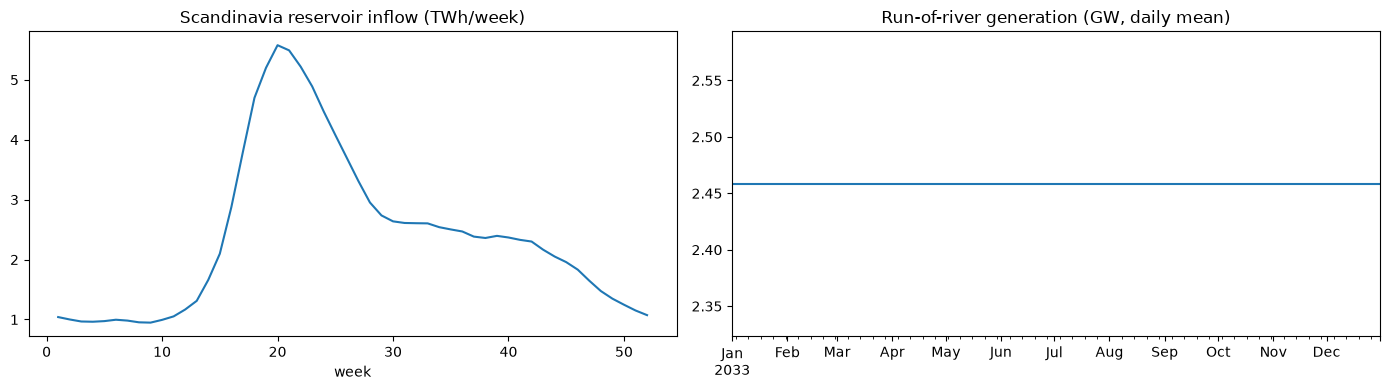

In [3]:
hyd = sm.build_hydro(2033, CY)
display(hyd["ror_cf_table"].assign(capacity_factor=lambda d: d.capacity_factor * 100).rename(columns={"capacity_factor": "capacity_factor_%"}))
print(f"Scandinavian RoR (CY {CY}): {hyd['ror_h'].sum()/1e6:.1f} TWh/yr, mean {hyd['ror_h'].mean()/1e3:.2f} GW "
      f"(capacity 2033: {hyd['caps']['hydro_ror']/1e3:.2f} GW)")
print(f"Reservoir inflow: {hyd['inflow_h'].sum()/1e6:.1f} TWh/yr, storage {hyd['caps']['hydro_reservoir_energy']/1e6:.1f} TWh, turbine {hyd['caps']['hydro_reservoir']/1e3:.1f} GW")

hydro_ts = pd.DataFrame({"ror_MW": hyd["ror_h"], "reservoir_inflow_MW": hyd["inflow_h"]},
                        index=pd.date_range("2033-01-01", periods=len(hyd["ror_h"]), freq="h"))
hydro_ts.to_csv(RES / "hydro_hourly.csv")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(hyd["inflow_weekly"] / 1e6).plot(ax=ax[0], title="Scandinavia reservoir inflow (TWh/week)")
hydro_ts["ror_MW"].resample("D").mean().div(1e3).plot(ax=ax[1], title="Run-of-river generation (GW, daily mean)")
plt.tight_layout(); plt.show()

## 3. Europe in the official model (today vs ERAA 2033 with interconnections ×2)

In [4]:
def europe_summary(run):
    f = next((HERE / "data/europe_runs" / run).glob("uc-summary_*.json"))
    return json.loads(f.read_text())

eu = {r: europe_summary(r) for r in ["baseline_2025", "reference_2033"]}
co2_eu = pd.DataFrame({r: {k: v / 1e3 for k, v in eu[r]["per_country_co2_emissions"].items()} for r in eu})
co2_eu.loc["EUROPE"] = co2_eu.sum()
co2_eu["change %"] = 100 * (co2_eu["reference_2033"] / co2_eu["baseline_2025"] - 1)
print("CO2 emissions per country in the official model (MtCO2/yr)")
display(co2_eu)
prices = {r: sm.load_europe_prices(r) for r in eu}
print("Neighbour prices used for Scandinavian trade (€/MWh)")
display(pd.concat({r: p.describe().T[["mean", "50%", "max"]] for r, p in prices.items()}))
print("Share of hours with price < 1 €/MWh:", {r: (p < 1).mean().round(2).to_dict() for r, p in prices.items()})

CO2 emissions per country in the official model (MtCO2/yr)


,baseline_2025,reference_2033,change %
ibe,0.00,0.00,100.00
pol,5.94,2.41,-59.39
sca,0.20,0.05,-75.76
ben,0.95,0.27,-71.59
fra,0.00,0.00,inf
ita,4.81,0.00,-99.98
ger,8.67,0.52,-94.06
EUROPE,20.57,3.25,-84.20


Neighbour prices used for Scandinavian trade (€/MWh)


mean  50%   max
baseline_2025  germany 15.99 9.00 40.00
               benelux 15.92 9.00 40.00
               poland  16.18 9.00 40.00
reference_2033 germany  5.05 0.20 56.00
               benelux  5.09 0.40 56.00
               poland   5.05 0.20 56.00

Share of hours with price < 1 €/MWh: {'baseline_2025': {'germany': 0.09, 'benelux': 0.09, 'poland': 0.09}, 'reference_2033': {'germany': 0.75, 'benelux': 0.75, 'poland': 0.75}}


## 4. Scenarios for Scandinavia

| Scenario | What is fixed | What the model chooses |
|---|---|---|
| **S0 today** | ERAA 2025 fleet, 2025 demand, 2025 borders | dispatch only → **CO₂ baseline** |
| **S1 ERAA plan** | ERAA 2033 fleet (new plants pay CAPEX), borders ×2 | dispatch |
| **S2 targets, min cost** | borders ×2; CO₂ ≤ 70 % of S0, wind+solar ≥ 1.4×, storage ≥ 1.2×, not a net importer | all investments & retirements |
| **S3 do more** | as S2, but CO₂ ≤ 10 % of S0, storage ≥ 2×, net exports ≥ ERAA-plan level | all investments & retirements |

Investment options: wind on/offshore, solar, batteries (4 h), new CCGT / OCGT. Coal, oil, biomass and fossil CHP can be kept or retired, not extended.
No new nuclear (cannot be online by 2033); hydro is fixed (potential already used).
Max. potential for wind/solar = 1.5 × ERAA 2033 plan (assumption).

In [5]:
pot = {k: 1.5 * c33[k] for k in VRES}
p25, p33 = prices["baseline_2025"], prices["reference_2033"]
results = {}

results["S0_today_2025"] = sm.solve(sm.Scenario("S0_today_2025", year=2025, cy=CY, invest=False, base_capacities=c25,
                                                intercos=ic25, prices=p25, co2_price=CO2_PRICE, min_net_export_MWh=None))
co2_base_t = results["S0_today_2025"]["summary"]["co2_Mt"] * 1e6

eraa_fixed = {k: c33[k] for k in VRES + ["batteries", "gas_ccgt", "gas_ocgt", "coal", "oil", "biofuel", "others_nonrenewable"]}
results["S1_eraa_plan_2033"] = sm.solve(sm.Scenario("S1_eraa_plan_2033", cy=CY, base_capacities=c25, fixed_capacities=eraa_fixed,
                                                    intercos=ic2x, prices=p33, co2_price=CO2_PRICE, min_net_export_MWh=None))
net_export_eraa = results["S1_eraa_plan_2033"]["summary"]["net_export_TWh"] * 1e6

results["S2_targets_min_cost"] = sm.solve(sm.Scenario(
    "S2_targets_min_cost", cy=CY, base_capacities=c25, intercos=ic2x, prices=p33, co2_price=CO2_PRICE,
    co2_cap_t=0.7 * co2_base_t, min_vres_MW=1.4 * vres25, min_storage_MW=1.2 * sto25, max_capacities=pot))

results["S3_do_more"] = sm.solve(sm.Scenario(
    "S3_do_more", cy=CY, base_capacities=c25, intercos=ic2x, prices=p33, co2_price=CO2_PRICE,
    co2_cap_t=0.1 * co2_base_t, min_vres_MW=1.4 * vres25, min_storage_MW=2.0 * sto25,
    min_net_export_MWh=net_export_eraa, max_capacities=pot))

print({k: r["status"] for k, r in results.items()})
summary = pd.DataFrame({k: r["summary"] for k, r in results.items()}).drop(["scenario", "status"])
display(summary)

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


{'S0_today_2025': 'Optimal', 'S1_eraa_plan_2033': 'Optimal', 'S2_targets_min_cost': 'Optimal', 'S3_do_more': 'Optimal'}


,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more
year,2025,2033,2033,2033
climatic_year,1989,1989,1989,1989
demand_TWh,419.82,507.38,507.38,507.38
co2_Mt,3.25,2.52,2.28,0.33
co2_cap_Mt,None,None,2.28,0.33
vres_capacity_GW,53.87,147.99,75.42,85.38
storage_capacity_GW,0.81,2.55,0.97,1.62
interconnection_GW,8.80,17.60,17.60,17.60
imports_TWh,12.11,0.00,40.64,12.33
exports_TWh,23.61,38.09,40.64,50.41


### 4.1 Do the scenarios meet the targets?

In [6]:
def check(s):
    return pd.Series({
        "CO2 vs 2025 (%)": 100 * (s["co2_Mt"] / (co2_base_t / 1e6) - 1),
        "-30% GHG": s["co2_Mt"] <= 0.7 * co2_base_t / 1e6 + 1e-6,
        "wind+solar vs 2025 (%)": 100 * (s["vres_capacity_GW"] * 1e3 / vres25 - 1),
        "RES +40%": s["vres_capacity_GW"] * 1e3 >= 1.4 * vres25 - 1,
        "storage vs 2025 (%)": 100 * (s["storage_capacity_GW"] * 1e3 / sto25 - 1),
        "storage +20%": s["storage_capacity_GW"] * 1e3 >= 1.2 * sto25 - 1,
        "interconnection vs 2025 (x)": s["interconnection_GW"] * 1e3 / sum(ic25.values()),
        "interco x2": s["interconnection_GW"] * 1e3 >= 2 * sum(ic25.values()) - 1,
        "no unserved energy": s["unserved_energy_GWh"] < 1e-3,
    })
target_check = pd.DataFrame({k: check(r["summary"]) for k, r in results.items()})
display(target_check)

,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more
CO2 vs 2025 (%),0.00,-22.43,-30.00,-90.00
-30% GHG,False,False,True,True
wind+solar vs 2025 (%),0.00,174.69,40.00,58.49
RES +40%,False,True,True,True
storage vs 2025 (%),0.00,215.13,20.00,100.00
storage +20%,False,True,True,True
interconnection vs 2025 (x),1.00,2.00,2.00,2.00
interco x2,False,True,True,True
no unserved energy,True,True,True,True


### 4.2 Capacities, new investments and retirements (GW)

,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more,change S3 vs 2025
nuclear,11.28,11.28,11.28,11.28,0.00
biofuel,3.27,2.65,0.00,-0.00,-3.27
gas_ccgt,3.32,1.89,3.32,3.32,0.00
gas_ocgt,0.00,0.00,0.00,0.00,0.00
coal,0.87,0.18,0.00,0.00,-0.87
oil,1.58,0.75,0.00,0.00,-1.58
others_renewable,6.99,6.86,6.86,6.86,-0.13
others_nonrenewable,0.74,0.57,0.51,0.05,-0.68
wind_onshore,39.32,71.70,56.03,70.83,31.51
wind_offshore,2.45,26.64,2.45,2.45,0.00


New capacity built after 2025 (GW):


,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more
wind_onshore,0.00,32.38,16.71,31.51
wind_offshore,0.00,24.20,0.00,0.00
solar_pv,0.00,37.54,4.84,0.00
batteries,0.00,1.74,0.16,0.81


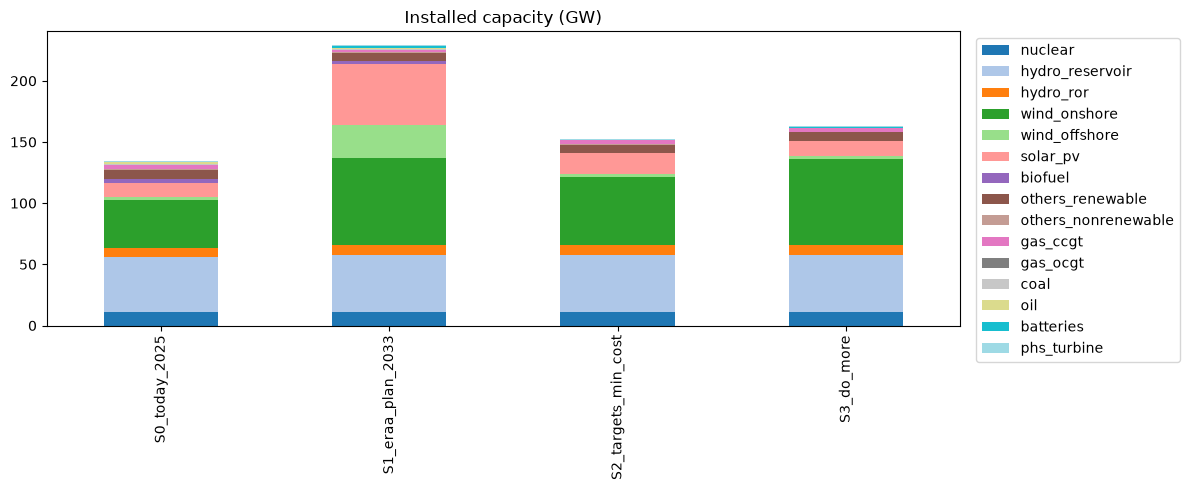

In [7]:
caps = pd.DataFrame({k: r["capacities_MW"] for k, r in results.items()}) / 1e3
caps["change S3 vs 2025"] = caps["S3_do_more"] - caps["S0_today_2025"]
display(caps)
new = pd.DataFrame({k: r["new_capacities_MW"] for k, r in results.items()}) / 1e3
print("New capacity built after 2025 (GW):"); display(new[(new.abs() > 1e-3).any(axis=1)])

ax = caps.drop(columns="change S3 vs 2025").T[["nuclear", "hydro_reservoir", "hydro_ror", "wind_onshore", "wind_offshore",
     "solar_pv", "biofuel", "others_renewable", "others_nonrenewable", "gas_ccgt", "gas_ocgt", "coal", "oil", "batteries",
     "phs_turbine"]].plot.bar(stacked=True, figsize=(12, 5), colormap="tab20", title="Installed capacity (GW)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

### 4.3 Annual energy balance (TWh), CO₂ and costs

In [8]:
energy = pd.DataFrame({k: r["energy_TWh"] for k, r in results.items()})
display(energy[(energy.abs() > 1e-3).any(axis=1)])
emis = pd.DataFrame({k: r["emissions_t"] for k, r in results.items()}) / 1e6
emis.loc["TOTAL"] = emis.sum()
print("CO2 emissions by technology (MtCO2/yr):"); display(emis[(emis.abs() > 1e-6).any(axis=1)])
costs = summary.loc[["cost_capex_MEUR", "cost_fom_MEUR", "cost_variable_MEUR", "cost_net_trade_MEUR", "cost_total_MEUR"]]
print("Annual system cost (M€/yr; negative trade = net export revenue):"); display(costs)
print("Cost assumptions:"); display(sm.tech_costs(CO2_PRICE))

,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more
demand,419.82,507.38,507.38,507.38
nuclear,84.58,1.12,98.75,98.33
biofuel,0.00,0.08,0.00,0.00
gas_ccgt,0.00,0.00,0.00,0.29
others_renewable,61.22,58.97,60.07,60.07
others_nonrenewable,6.44,5.00,4.51,0.46
wind_onshore,116.15,222.16,174.04,220.02
wind_offshore,7.72,96.11,11.13,11.13
solar_pv,9.41,36.37,13.19,9.42
hydro_ror,21.53,2.17,21.54,21.53


CO2 emissions by technology (MtCO2/yr):


,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more
gas_ccgt,0.00,0.00,0.00,0.09
others_nonrenewable,3.25,2.52,2.28,0.23
TOTAL,3.25,2.52,2.28,0.33


Annual system cost (M€/yr; negative trade = net export revenue):


,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more
cost_capex_MEUR,0.00,"9,517.14","1,641.70","2,807.19"
cost_fom_MEUR,"2,343.92","3,982.11","2,464.21","2,603.67"
cost_variable_MEUR,785.10,33.64,915.66,931.03
cost_net_trade_MEUR,-764.66,-752.20,-663.67,-725.45
cost_total_MEUR,"2,364.36","12,780.69","4,357.90","5,616.44"


Cost assumptions:


,capex_EUR_per_kW,annuity_EUR_per_MW_yr,fom_EUR_per_MW_yr,fuel_EUR_per_MWh,co2_t_per_MWh,co2_cost_EUR_per_MWh,vom_EUR_per_MWh,var_cost_EUR_per_MWh
nuclear,"4,500.00","198,908.30","115,000.00",1.76,0.00,0.00,7.40,9.16
wind_onshore,"1,200.00","85,142.95","14,000.00",0.00,0.00,0.00,0.00,0.00
wind_offshore,"2,200.00","206,093.31","31,000.00",0.00,0.00,0.00,0.20,0.20
solar_pv,500.00,"40,121.29","14,000.00",0.00,0.00,0.00,0.00,0.00
biofuel,"1,500.00","125,790.24","40,000.00",36.67,0.00,0.00,3.60,40.27
gas_ccgt,"1,000.00","88,827.43","21,000.00",37.44,0.32,25.65,2.10,65.19
gas_ocgt,600.00,"53,296.46","12,000.00",71.47,0.61,48.97,1.90,122.34
coal,"1,800.00","154,445.88","40,000.00",30.83,0.76,60.62,3.00,94.46
oil,500.00,"50,926.10","10,000.00",144.81,0.81,64.73,2.60,212.14
hydro_ror,"1,600.00","74,480.32","8,000.00",0.00,0.00,0.00,0.40,0.40


### 4.4 Trade with each neighbour (TWh, + = import to Scandinavia)

In [9]:
trade = pd.DataFrame({k: {n: r["hourly"][f"net_import_{n}"].sum() / 1e6 for n in sm.NEIGHBOURS} for k, r in results.items()})
display(trade)

,S0_today_2025,S1_eraa_plan_2033,S2_targets_min_cost,S3_do_more
germany,-8.83,-29.56,1.35,-29.35
benelux,-1.89,-5.86,-2.04,-5.78
poland,-0.78,-2.66,0.69,-2.96


### 4.5 Hourly operation of the S3 plan — a winter and a summer week

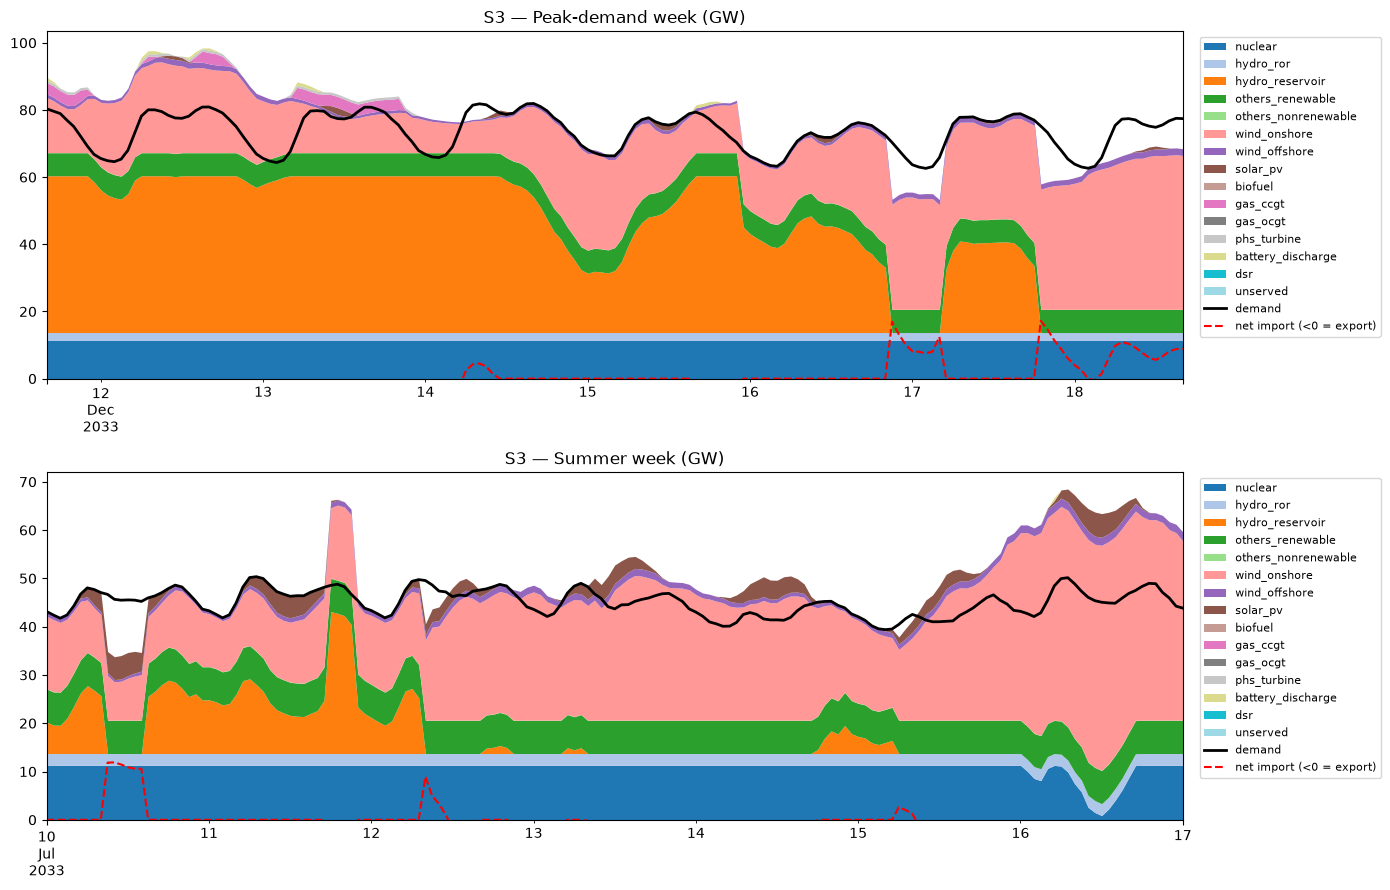

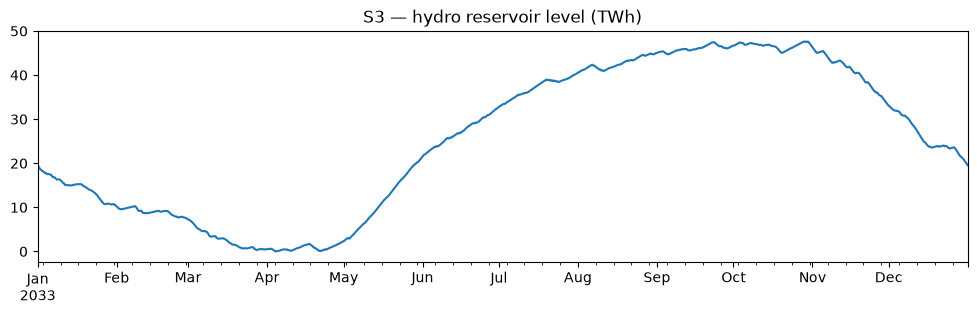

In [10]:
h = results["S3_do_more"]["hourly"]
stack = ["nuclear", "hydro_ror", "hydro_reservoir", "others_renewable", "others_nonrenewable", "wind_onshore",
         "wind_offshore", "solar_pv", "biofuel", "gas_ccgt", "gas_ocgt", "phs_turbine", "battery_discharge", "dsr", "unserved"]
h["net_import"] = h[[f"net_import_{n}" for n in sm.NEIGHBOURS]].sum(axis=1)
peak_day = h["demand"].idxmax()
weeks = {"Peak-demand week": peak_day - pd.Timedelta(days=3), "Summer week": pd.Timestamp("2033-07-10")}
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
for ax, (title, start) in zip(axes, weeks.items()):
    w = h.loc[start: start + pd.Timedelta(days=7)]
    (w[stack].clip(lower=0) / 1e3).plot.area(ax=ax, stacked=True, linewidth=0, colormap="tab20")
    (w["demand"] / 1e3).plot(ax=ax, color="k", lw=2, label="demand")
    (w["net_import"] / 1e3).plot(ax=ax, color="r", lw=1.5, ls="--", label="net import (<0 = export)")
    ax.set_title(f"S3 — {title} (GW)"); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
(h["reservoir_soc_TWh"]).plot(figsize=(12, 3), title="S3 — hydro reservoir level (TWh)"); plt.show()

## 5. Robustness: S3 plan over all climatic years

Same capacities, dispatch only, for every climatic year available (neighbour prices from CY 1989).

In [11]:
s3_caps = dict(results["S3_do_more"]["capacities_MW"])
s3_caps["batteries_energy"] = s3_caps["batteries"] * sm.BATTERY["duration_h"]
robust = {}
for cy in [1982, 1989, 1996, 2003, 2010, 2016]:
    r = sm.solve(sm.Scenario(f"S3_cy{cy}", cy=cy, invest=False, base_capacities=s3_caps, intercos=ic2x, prices=p33,
                             co2_price=CO2_PRICE, min_net_export_MWh=None))
    robust[cy] = r["summary"] if r["status"] == "Optimal" else {"status": r["status"]}
robust = pd.DataFrame(robust).T[["demand_TWh", "co2_Mt", "net_export_TWh", "unserved_energy_GWh", "unserved_hours",
                                  "vres_curtailment_pct", "renewable_share_pct", "cost_total_MEUR"]]
display(robust)

,demand_TWh,co2_Mt,net_export_TWh,unserved_energy_GWh,unserved_hours,vres_curtailment_pct,renewable_share_pct,cost_total_MEUR
1982,525.16,0.23,-84.78,0.00,0,0.16,71.66,"2,219.85"
1989,507.38,0.23,-59.59,0.00,0,0.35,75.83,"2,004.13"
1996,520.81,0.23,-94.60,0.00,0,0.36,68.12,"2,334.64"
2003,513.96,0.23,-91.28,0.00,0,0.28,69.95,"2,215.67"
2010,528.92,0.23,-95.34,0.00,0,0.21,66.39,"2,456.65"
2016,510.28,0.23,-93.24,0.00,0,0.33,69.50,"2,183.73"



**How to read this table.** No unserved energy and CO₂ stays at 0.23 Mt in every climatic year, so the S3 fleet is **adequate and clean in all weather years**.
The negative net exports here are a model artefact: without the export commitment of S3, the model imports neighbours' surplus power, which costs almost nothing in 2033 (price < 1 €/MWh in 75 % of hours) and is treated as unlimited (price-taker assumption). In S3 itself, exports are a **policy commitment** (net exports ≥ the ERAA-plan level), not something the 2033 market prices pay for.


## 6. Plans in the official game format + check in the European model

`scandinavia_S2.json` and `scandinavia_S3.json` are written in `results/` in the format of `input/long_term_uc/countries/scandinavia.json`.
Each is run in the official model (all other countries at ERAA 2033, interconnections ×2), to see the effect on **Europe's** CO₂ and adequacy.

In [12]:
OFFICIAL_MAP = {"wind_onshore": ["wind_onshore"], "wind_offshore": ["wind_offshore"], "solar_pv": ["solar_pv"],
                "nuclear": ["nuclear"], "biofuel": ["biofuel"], "gas": ["gas_ccgt", "gas_ocgt"], "coal": ["coal"],
                "oil": ["oil"], "others_fatal": ["others_renewable", "others_nonrenewable"], "batteries": ["batteries"],
                "hydro_run_of_river": ["hydro_ror"], "hydro_reservoir": ["hydro_reservoir"],
                "hydro_pump_storage_open_loop": ["phs_turbine"], "dsr": ["dsr"]}

def to_official_json(capacities, path):
    caps = {agg: round(sum(capacities.get(k, 0.0) for k in ks), 1) for agg, ks in OFFICIAL_MAP.items()}
    keep = [agg for agg, v in caps.items() if v > 0] + ["failure"]
    d = {"team": "scandinavia", "selected_prod_types": {"scandinavia": keep},
         "capacities_tb_overwritten": {"scandinavia": {k: v for k, v in caps.items() if v > 0}}}
    path.write_text(json.dumps(d, indent=2)); return d

official = {}
for s in ["S2_targets_min_cost", "S3_do_more"]:
    tag = s.split("_")[0]
    f = RES / f"scandinavia_{tag}.json"
    to_official_json(results[s]["capacities_MW"], f)
    for attempt in range(3):  # the official model occasionally fails at network build; retry
        run = subprocess.run([sys.executable, str(HERE / "run_europe_model.py"), f"plan_{tag}", str(f)],
                             cwd=HERE.parent, capture_output=True, text=True)
        if run.returncode == 0:
            break
    print(run.stdout[-300:])
    if run.returncode != 0:
        raise RuntimeError(run.stderr[-1500:])
    official[f"plan_{tag}"] = europe_summary(f"plan_{tag}")

off = {**eu, **official}
co2_off = pd.DataFrame({r: {k: v / 1e3 for k, v in d["per_country_co2_emissions"].items()} for r, d in off.items()})
co2_off.loc["EUROPE"] = co2_off.sum()
print("Official model — CO2 per country (MtCO2/yr)"); display(co2_off)
ens_off = pd.DataFrame({r: d["per_country_ens"] for r, d in off.items()}) / 1e3
print("Official model — energy not served (GWh)"); display(ens_off)
print("Official model — total operational cost Europe (M€):", {r: round(d["total_operational_cost"]) for r, d in off.items()})

plan_S2: done -> /Users/farukavci/EELISA-Paris/ElectricSystemPlanning_ENPC2026_Europe1/scandinavia-2033/data/europe_runs/plan_S2



plan_S3: done -> /Users/farukavci/EELISA-Paris/ElectricSystemPlanning_ENPC2026_Europe1/scandinavia-2033/data/europe_runs/plan_S3

Official model — CO2 per country (MtCO2/yr)


,baseline_2025,reference_2033,plan_S2,plan_S3
ibe,0.00,0.00,0.01,0.00
pol,5.94,2.41,3.66,3.42
sca,0.20,0.05,0.34,0.30
ben,0.95,0.27,0.57,0.44
fra,0.00,0.00,0.00,0.00
ita,4.81,0.00,0.00,0.00
ger,8.67,0.52,1.18,0.91
EUROPE,20.57,3.25,5.76,5.09


Official model — energy not served (GWh)


,baseline_2025,reference_2033,plan_S2,plan_S3
ben,0.00,0.00,0.00,0.00
fra,0.00,0.00,0.00,0.00
ger,0.00,0.00,0.00,0.00
ibe,0.00,0.00,0.00,0.00
ita,0.00,0.00,0.00,0.00
pol,0.00,0.00,0.00,0.00
sca,0.00,0.00,0.00,0.00


Official model — total operational cost Europe (M€): {'baseline_2025': 6216, 'reference_2033': 2776, 'plan_S2': 3488, 'plan_S3': 3251}


## 7. Save everything

In [13]:
with pd.ExcelWriter(RES / "scandinavia_2033_results.xlsx") as xw:
    targets.to_excel(xw, sheet_name="targets")
    target_check.astype(str).to_excel(xw, sheet_name="target_check")
    summary.to_excel(xw, sheet_name="summary")
    caps.to_excel(xw, sheet_name="capacities_GW")
    new.to_excel(xw, sheet_name="new_capacity_GW")
    energy.to_excel(xw, sheet_name="energy_TWh")
    emis.to_excel(xw, sheet_name="co2_Mt")
    costs.to_excel(xw, sheet_name="costs_MEUR")
    trade.to_excel(xw, sheet_name="trade_TWh")
    robust.to_excel(xw, sheet_name="robustness_CY")
    co2_off.to_excel(xw, sheet_name="europe_co2_official")
    ens_off.to_excel(xw, sheet_name="europe_ens_official")
    hyd["ror_cf_table"].to_excel(xw, sheet_name="hydro_ror_cf")
    sm.tech_costs(CO2_PRICE).to_excel(xw, sheet_name="cost_assumptions")
for k, r in results.items():
    r["hourly"].to_csv(RES / f"hourly_{k}.csv")
summary.to_csv(RES / "summary.csv"); caps.to_csv(RES / "capacities_GW.csv"); energy.to_csv(RES / "energy_TWh.csv")
print("Saved to", RES); print(sorted(p.name for p in RES.iterdir()))

Saved to /Users/farukavci/EELISA-Paris/ElectricSystemPlanning_ENPC2026_Europe1/scandinavia-2033/results
['capacities_GW.csv', 'energy_TWh.csv', 'hourly_S0_today_2025.csv', 'hourly_S1_eraa_plan_2033.csv', 'hourly_S2_targets_min_cost.csv', 'hourly_S3_do_more.csv', 'hydro_hourly.csv', 'scandinavia_2033_results.xlsx', 'scandinavia_S2.json', 'scandinavia_S3.json', 'summary.csv']
